# 10 — DB5 LDA baseline in the repo pipeline

The baseline of `01`–`05` (the MATLAB port) run through `src/`: the same causal pipeline as the online path,
splits by repetition, one protocol for every training regime. Later notebooks (`11`–`15`) add decoders to the same table.

Prerequisites: `python scripts/fetch_ninapro.py --db 5 --exercises 1` and `python scripts/build_features.py`
(`params.yaml`: 16 channels at 200 Hz, MAV / RMS / WL, 200 ms windows every 50 ms, train on repetitions 1–4, test on 5–6).

Regimes (`evaluation.regime`):
- **per_user**: one decoder per subject, the repo default.
- **pooled**: one decoder for all subjects, tested on their held-out repetitions (`01`–`05`).
- **loso**: leave one subject out, the decoder never saw the test subject; the calibration curve adapts it with the first
  *n* seconds per class of that subject (`LDA.adapt`).

`evaluation.normalize`: `global` z-scores everyone with one set of statistics (`05`), `user` with each subject's own
(from their training windows, labels unused, like a calibration recording).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import evaluation
from src.config import load_config

if Path.cwd().name == "notebooks":
    os.chdir("..")

cfg = load_config()
X, y, columns, info = evaluation.load_features(cfg)
print(f"{len(y)} windows x {X.shape[1]} features, {len(np.unique(y))} classes, rest {np.mean(y == 0):.0%} of windows")

140145 windows x 48 features, 13 classes, rest 63% of windows


## Every regime

`lda` with `shrinkage: 0` is the baseline's classifier (plain LDA, uniform priors). `05` additionally skips the filter;
on these windows that changes balanced accuracy by about 0.01, so it is left out here.

Accuracy is dominated by rest (~60 % of the windows): **balanced accuracy** (mean recall over the 13 classes) and
macro-F1 are the numbers to compare.

In [2]:
VARIANTS = {
    "baseline (05): pooled, global norm, no shrinkage": {
        "evaluation": {"regime": "pooled", "normalize": "global"},
        "decoder": {"params": {"shrinkage": 0.0, "priors": "uniform"}},
    },
    "pooled, global norm": {"evaluation": {"regime": "pooled", "normalize": "global"}},
    "pooled, per-user norm": {"evaluation": {"regime": "pooled", "normalize": "user"}},
    "loso, per-user norm": {"evaluation": {"regime": "loso", "normalize": "user"}},
    "per_user": {"evaluation": {"regime": "per_user"}},
}

rows, results = [], {}
for name, overrides in VARIANTS.items():
    c = load_config(overrides=overrides)
    results[name] = evaluation.evaluate(X, y, columns, info, c)
    test = results[name][0]["test"]
    per_user = [u["balanced_accuracy"] for u in results[name][0]["per_user"].values()]
    rows.append(
        {
            "variant": name,
            "accuracy": test["accuracy"],
            "balanced_accuracy": test["balanced_accuracy"],
            "macro_f1": test["macro_f1"],
            "worst_user_bal": min(per_user),
            "best_user_bal": max(per_user),
            "switches_per_s": test["switches_per_s"],
        }
    )
table = pd.DataFrame(rows).set_index("variant")
table.round(3)

,accuracy,balanced_accuracy,macro_f1,worst_user_bal,best_user_bal,switches_per_s
variant,,,,,,
"baseline (05): pooled, global norm, no shrinkage",0.695,0.412,0.414,0.285,0.520,4.712
"pooled, global norm",0.692,0.403,0.405,0.288,0.511,3.631
"pooled, per-user norm",0.730,0.461,0.467,0.291,0.577,3.519
"loso, per-user norm",0.701,0.389,0.393,0.234,0.557,3.690
per_user,0.810,0.643,0.653,0.566,0.701,2.468


## Calibration effort

Balanced accuracy on the test repetitions after *n* seconds per class of the test subject: **per_user** fits a new LDA on
them, **loso** adapts the LDA of the other nine subjects (`LDA.adapt`, means and covariance blended 50/50).

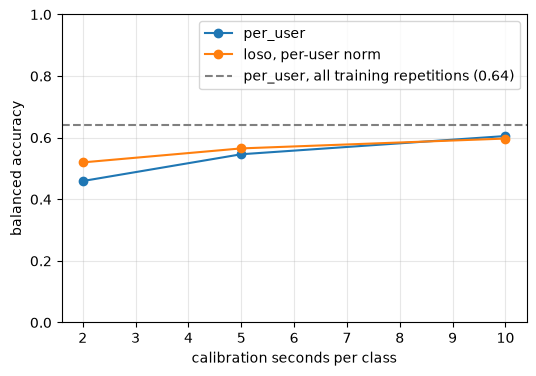

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
for name in ("per_user", "loso, per-user norm"):
    curve = results[name][0]["calibration"]
    seconds = [float(s) for s in curve]
    ax.plot(seconds, [c["balanced_accuracy"] for c in curve.values()], "o-", label=name)
full = table.loc["per_user", "balanced_accuracy"]
ax.axhline(full, ls="--", c="grey", label=f"per_user, all training repetitions ({full:.2f})")
ax.set(xlabel="calibration seconds per class", ylabel="balanced accuracy", ylim=(0, 1))
ax.legend()
ax.grid(alpha=0.3)

## Confusions of the per-user LDA

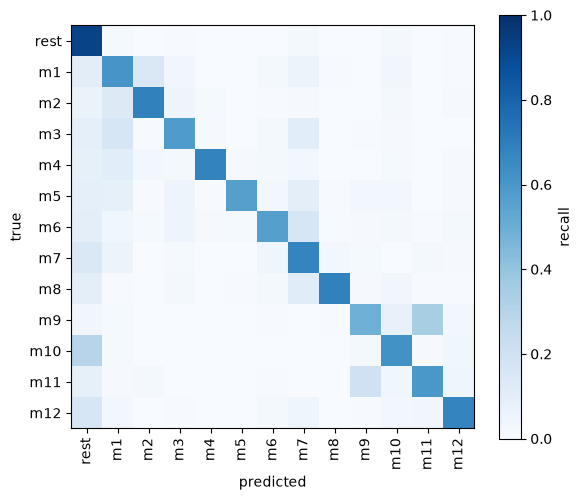

In [4]:
_, y_true, y_pred = results["per_user"]
classes = np.unique(y_true)
cm = evaluation.confusion(y_true, y_pred, classes)
recall = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(recall, vmin=0, vmax=1, cmap="Blues")
names = [info["label_names"][c] for c in classes]
ax.set(xticks=range(len(classes)), yticks=range(len(classes)), xlabel="predicted", ylabel="true")
ax.set_xticklabels(names, rotation=90)
ax.set_yticklabels(names)
fig.colorbar(im, label="recall")

In [5]:
models = evaluation.final_models(X, y, columns, info["columns"], info["feature_names"], cfg, cfg.hash)
normalizer, decoder = next(iter(models.values()))
print(f"LDA decision: {evaluation.decoder_latency_us(decoder, normalizer, X):.0f} µs per window")

LDA decision: 7 µs per window


## Summary for the comparison (`15`)

The regimes again through `src/report.py` (same numbers as above), saved to `runs/notebooks/lda.json`.

In [6]:
from src import report

summary = report.run_regimes({}, (X, y, columns, info))
report.save("lda", summary, report.latency_us({}, (X, y, columns, info)))

per_user balanced 0.643 | macro-F1 0.653 | 1 s
pooled   balanced 0.461 | macro-F1 0.467 | 0 s


loso     balanced 0.389 | macro-F1 0.393 | 2 s
